In [11]:
import pandas as pd

df = pd.read_csv("../out.csv")

df

,DataHora,Municipio,Bioma,DiaSemChuva,Precipitacao,RiscoFogo,Fogo,PeriodoSecura
0,2026-05,SANTA CRUZ DA CONCEIÇÃO,3.0,7.000000,0.0000,1.000000,1,100.209227
1,2025-06,COSMORAMA,3.0,4.000000,0.0000,1.000000,1,103.497860
2,2026-02,PEREIRA BARRETO,1.7,2.000000,2.4950,0.065000,1,104.934850
3,2025-08,DUARTINA,1.7,5.666667,0.0000,0.990000,1,103.954089
4,2025-09,BOITUVA,1.7,36.833333,1.1775,0.935000,1,103.898038
...,...,...,...,...,...,...,...,...
1216,2025-07,CASTILHO,1.7,4.000000,0.0000,0.479776,0,101.521128
1217,2025-08,CASTILHO,1.7,4.000000,0.0000,0.701831,0,103.508245
1218,2025-09,CASTILHO,1.7,3.000000,0.0000,0.794828,0,104.409623
1219,2025-11,CASTILHO,1.7,0.000000,0.3000,0.586618,0,81.465682


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X = df[["Bioma", "DiaSemChuva", "Precipitacao", "PeriodoSecura", "RiscoFogo"]]
y = df["Fogo"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [13]:
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.neural_network import MLPClassifier

mlp = MLPClassifier(
    hidden_layer_sizes=(8),
    activation='relu',
    solver='adam',
    max_iter=500,
    random_state=42
)

mlp.fit(X_train_scaled, y_train)

y_pred = mlp.predict(X_test_scaled)
print(f"Acurácia: {accuracy_score(y_test, y_pred):.4f}\n")
print("Matriz de Confusão:")
print(confusion_matrix(y_test, y_pred))
print("\nRelatório de Classificação:")
print(classification_report(y_test, y_pred))

Acurácia: 0.9510

Matriz de Confusão:
[[205   2]
 [ 10  28]]

Relatório de Classificação:
              precision    recall  f1-score   support

           0       0.95      0.99      0.97       207
           1       0.93      0.74      0.82        38

    accuracy                           0.95       245
   macro avg       0.94      0.86      0.90       245
weighted avg       0.95      0.95      0.95       245



/home/erick/Documentos/queimadas/.venv/lib/python3.14/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(


In [14]:
from sklearn.gaussian_process.kernels import RBF, ConstantKernel
from sklearn.model_selection import train_test_split
from sklearn.gaussian_process import GaussianProcessClassifier

kernel = ConstantKernel(1.0, (1e-3, 1e3)) * RBF(
    length_scale=[1.0] * X_train_scaled.shape[1], 
    length_scale_bounds=(1e-2, 1e2)
)

gpc = GaussianProcessClassifier(
    kernel=kernel,
    random_state=42,
    n_jobs=-1
)

gpc.fit(X_train_scaled, y_train)

y_pred = gpc.predict(X_test_scaled)
y_prob = gpc.predict_proba(X_test_scaled)

print(f"Acurácia: {accuracy_score(y_test, y_pred):.4f}\n")
print("Matriz de Confusão:")
print(confusion_matrix(y_test, y_pred))
print("\nRelatório de Classificação:")
print(classification_report(y_test, y_pred))

Acurácia: 0.9673

Matriz de Confusão:
[[207   0]
 [  8  30]]

Relatório de Classificação:
              precision    recall  f1-score   support

           0       0.96      1.00      0.98       207
           1       1.00      0.79      0.88        38

    accuracy                           0.97       245
   macro avg       0.98      0.89      0.93       245
weighted avg       0.97      0.97      0.97       245



In [15]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

lr = LogisticRegression(
    random_state=42,
    n_jobs=-1,
    max_iter=1000
)

lr.fit(X_train_scaled, y_train)

y_pred = lr.predict(X_test_scaled)
y_prob = lr.predict_proba(X_test_scaled)

print(f"Acurácia: {accuracy_score(y_test, y_pred):.4f}\n")
print("Matriz de Confusão:")
print(confusion_matrix(y_test, y_pred))
print("\nRelatório de Classificação:")
print(classification_report(y_test, y_pred))

Acurácia: 0.9020

Matriz de Confusão:
[[206   1]
 [ 23  15]]

Relatório de Classificação:
              precision    recall  f1-score   support

           0       0.90      1.00      0.94       207
           1       0.94      0.39      0.56        38

    accuracy                           0.90       245
   macro avg       0.92      0.69      0.75       245
weighted avg       0.91      0.90      0.88       245



/home/erick/Documentos/queimadas/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)


In [18]:
teste = pd.DataFrame([
    {
        "Bioma": 1.7,
        "DiaSemChuva": 20,
        "Precipitacao": 0,
        "PeriodoSecura": 30,
        "RiscoFogo": 1,
    }
])

teste_s = scaler.transform(teste)

print(f'Probabilidade de incêndio (MLP): {mlp.predict_proba(teste_s)[0][1]:.2f}')
print(f'Probabilidade de incêndio (GPC): {gpc.predict_proba(teste_s)[0][1]:.2f}')
print(f'Probabilidade de incêndio (LR): {lr.predict_proba(teste_s)[0][1]:.2f}')

Probabilidade de incêndio (MLP): 0.95
Probabilidade de incêndio (GPC): 0.68
Probabilidade de incêndio (LR): 0.56


/home/erick/Documentos/queimadas/.venv/lib/python3.14/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/home/erick/Documentos/queimadas/.venv/lib/python3.14/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/home/erick/Documentos/queimadas/.venv/lib/python3.14/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/home/erick/Documentos/queimadas/.venv/lib/python3.14/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/home/erick/Documentos/queimadas/.venv/lib/python3.14/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not ha

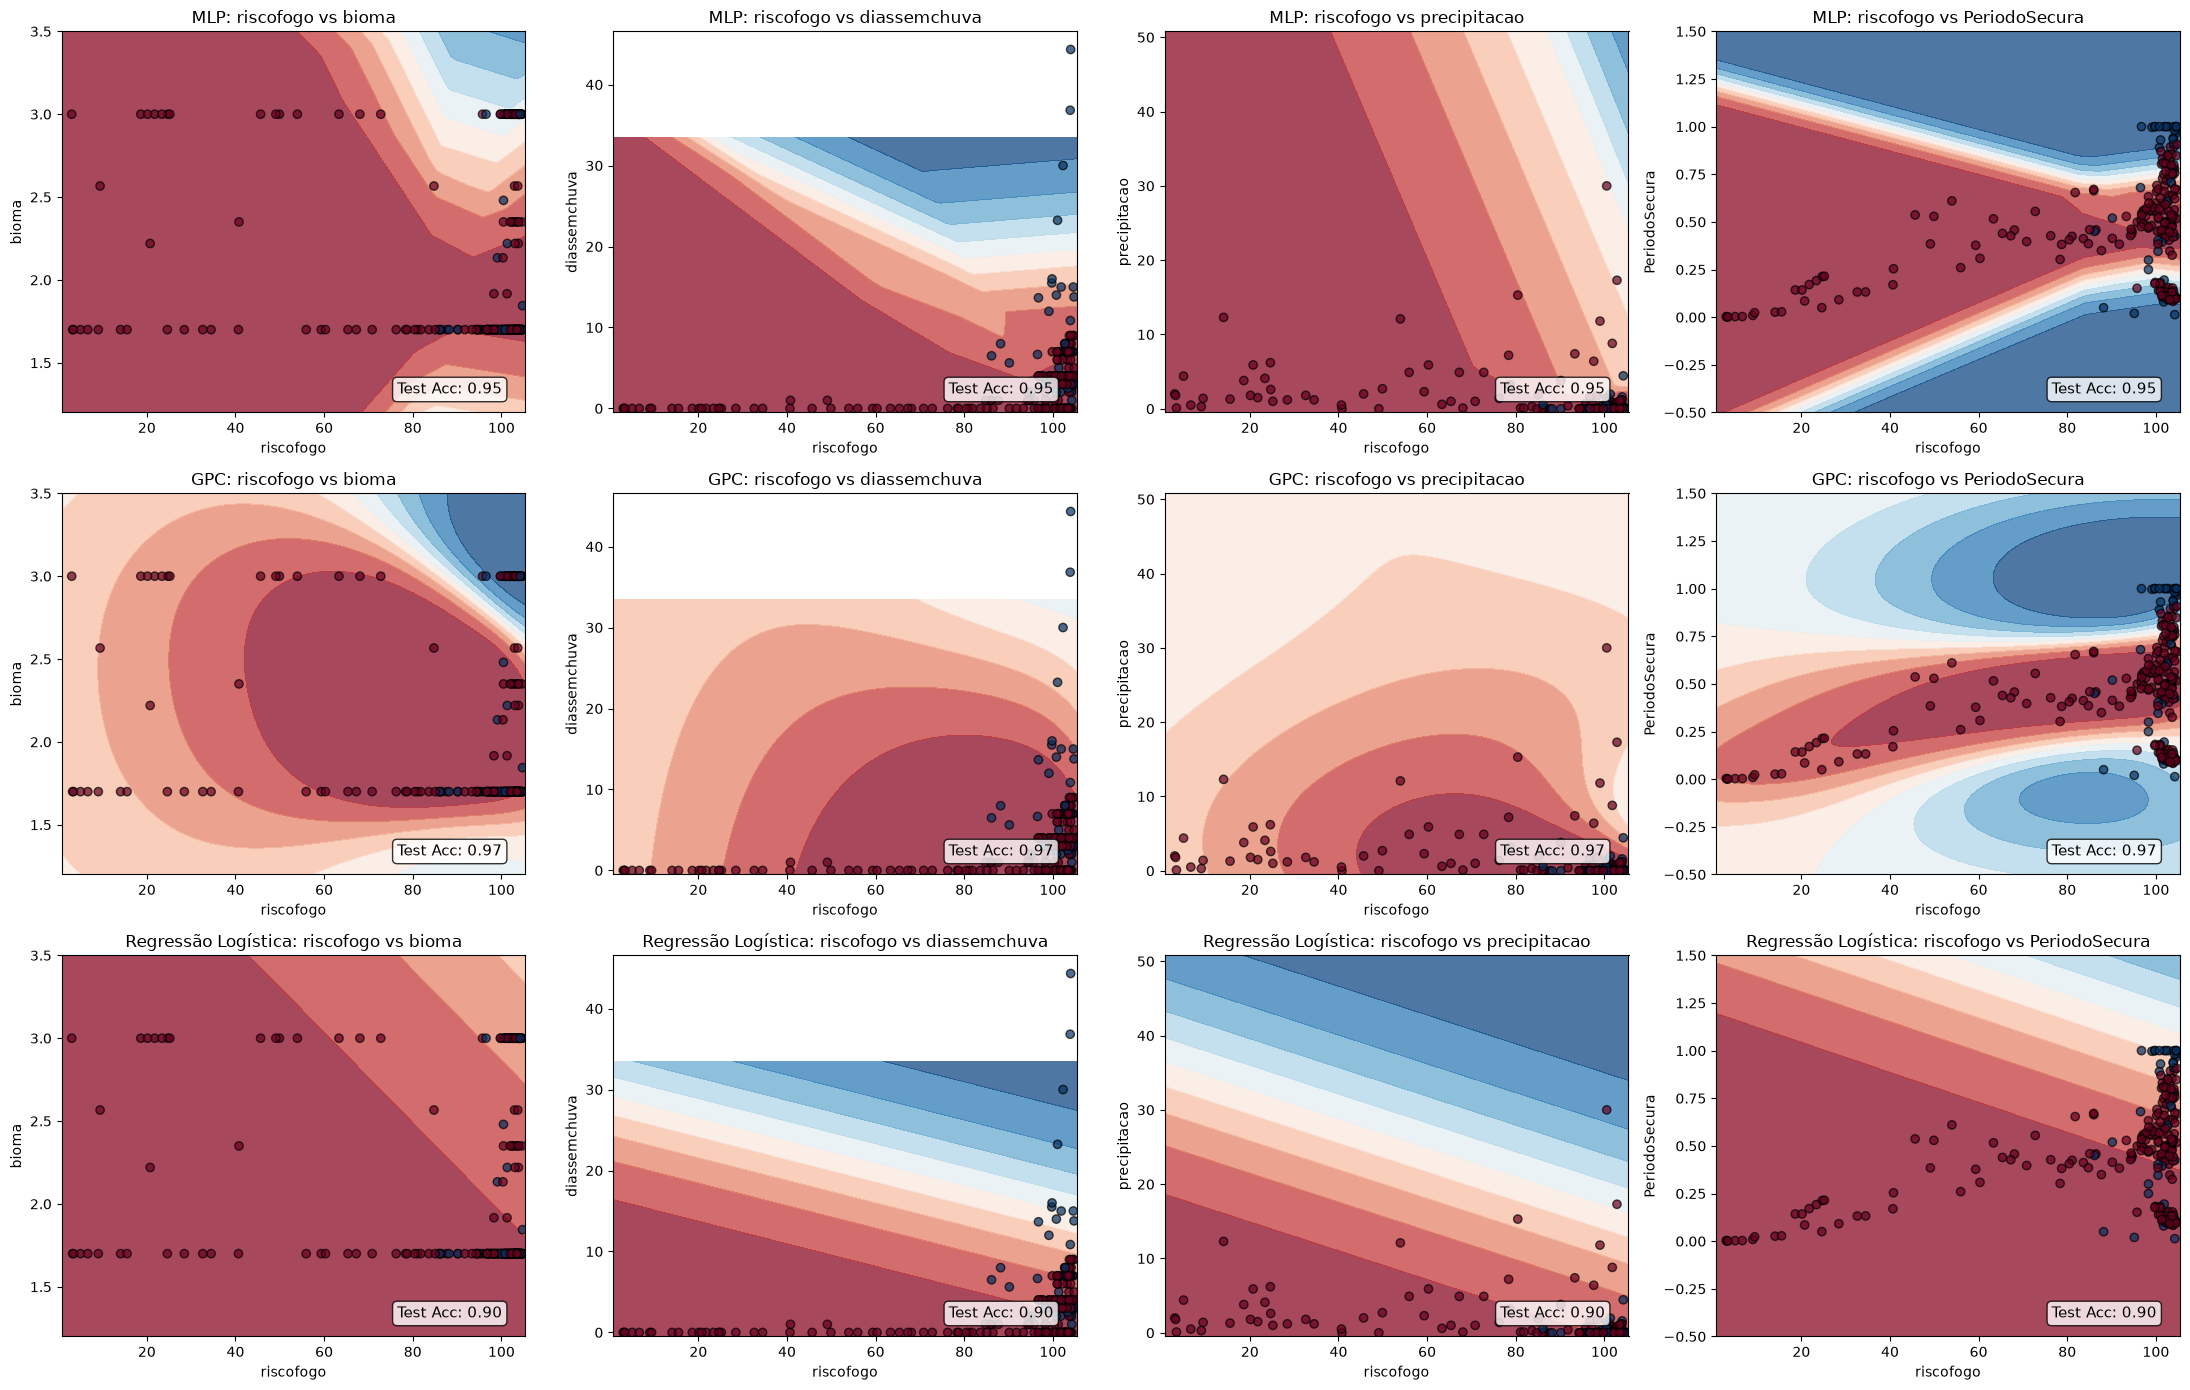

In [19]:
import numpy as np
import matplotlib.pyplot as plt

# Garante a conversão para array NumPy se forem DataFrames do Pandas
X_tr = X_train.to_numpy() if hasattr(X_train, "to_numpy") else X_train
X_te = X_test.to_numpy() if hasattr(X_test, "to_numpy") else X_test
y_tr = y_train.to_numpy() if hasattr(y_train, "to_numpy") else y_train
y_te = y_test.to_numpy() if hasattr(y_test, "to_numpy") else y_test

# Setup de colunas e features (Adicionado 'PeriodoSecura')
# ATENÇÃO: Verifique a ordem real das colunas no seu dataset.
# Aqui assumimos que 'PeriodoSecura' seja a 5ª coluna (índice 4).
features = ["bioma", "diassemchuva", "precipitacao", "riscofogo", "PeriodoSecura"]
rf_idx = 3  # Índice do riscofogo
other_indices = [0, 1, 2, 4]  # bioma, diassemchuva, precipitacao, PeriodoSecura

mean_unscaled = X_tr.mean(axis=0)

# Alterado para 3 linhas e 4 colunas (3x4 subplots) e ajustado o tamanho da figura
fig, axes = plt.subplots(3, 4, figsize=(22, 14))

models_info = [
    ("MLP", mlp, axes[0]), 
    ("GPC", gpc, axes[1]),
    ("Regressão Logística", lr, axes[2])
]

for model_name, model, row_axes in models_info:
    for i, other_idx in enumerate(other_indices):
        ax = row_axes[i]

        # Limites na escala original das features
        x_min, x_max = X_tr[:, rf_idx].min() - 0.5, X_tr[:, rf_idx].max() + 0.5
        y_min, y_max = (
            X_tr[:, other_idx].min() - 0.5,
            X_tr[:, other_idx].max() + 0.5,
        )

        xx, yy = np.meshgrid(
            np.linspace(x_min, x_max, 100), np.linspace(y_min, y_max, 100)
        )

        # Matriz para predizer probabilidade
        grid_unscaled = np.tile(mean_unscaled, (xx.ravel().shape[0], 1))
        grid_unscaled[:, rf_idx] = xx.ravel()
        grid_unscaled[:, other_idx] = yy.ravel()
        grid_scaled = scaler.transform(grid_unscaled)

        Z = model.predict_proba(grid_scaled)[:, 1].reshape(xx.shape)

        # Plot
        ax.contourf(xx, yy, Z, levels=np.linspace(0, 1, 11), cmap=plt.cm.RdBu, vmin=0, vmax=1, alpha=0.75)
        ax.scatter(
            X_te[:, rf_idx],
            X_te[:, other_idx],
            c=y_te,
            cmap=plt.cm.RdBu,   # mesmo cmap do fundo
            vmin=0, vmax=1,
            edgecolors="k",
            alpha=0.7,
        )

        ax.set_xlabel("riscofogo")
        ax.set_ylabel(features[other_idx])
        ax.set_title(f"{model_name}: riscofogo vs {features[other_idx]}")

        acc = model.score(X_test_scaled, y_te)
        ax.text(
            0.95,
            0.05,
            f"Test Acc: {acc:.2f}",
            transform=ax.transAxes,
            size=11,
            horizontalalignment="right",
            bbox=dict(boxstyle="round", facecolor="white", alpha=0.8),
        )

plt.tight_layout()
plt.show()

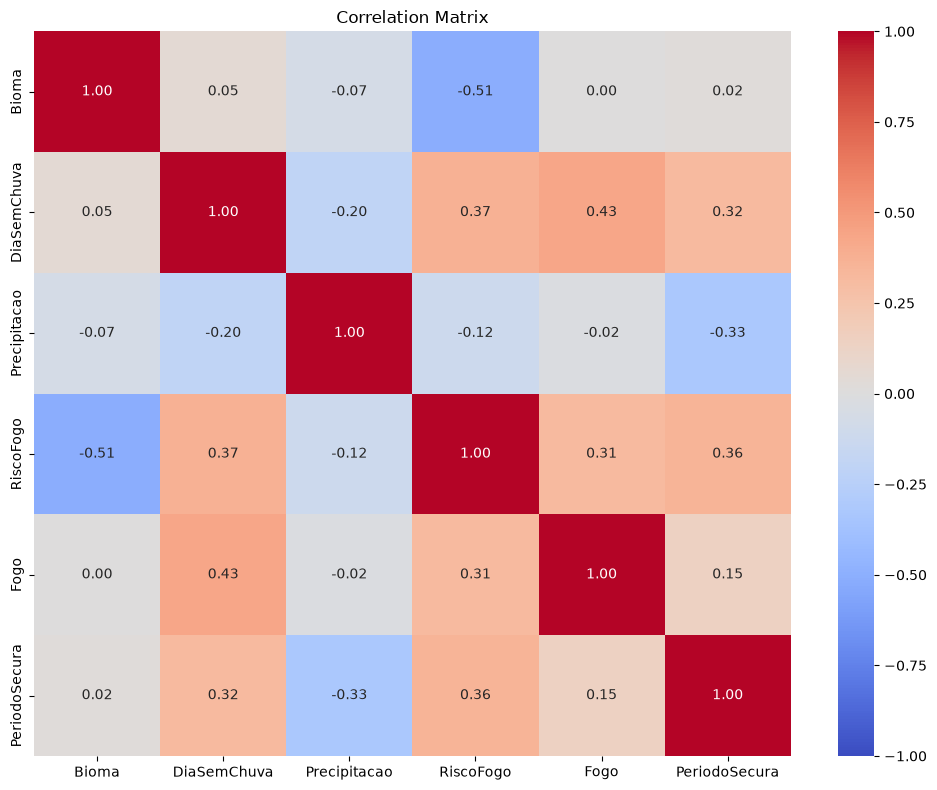

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# df is your pandas DataFrame
corr = df.select_dtypes(include="number").corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, cmap="coolwarm", vmin=-1, vmax=1, fmt=".2f")
plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()
